# Car Price Prediction
**Oasis Infobyte SIP — Data Science Task 3** · Steven Manuel Rios

Dataset: *Vehicle dataset from CarDekho* (`data/car_data.csv`, 301 used cars, prices in lakh ₹). Goal: predict `Selling_Price`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
def save(name): plt.tight_layout(); plt.savefig(f"screenshots/{name}.png", dpi=110); plt.show()

In [2]:
df = pd.read_csv("data/car_data.csv")
print(df.shape); df.head()

(301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


## 1. Data cleaning

In [3]:
print("Nulls:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates().dropna().reset_index(drop=True)
# normalise categorical text (e.g. 'Petrol' vs 'petrol', stray whitespace)
for c in ["Car_Name", "Fuel_Type", "Seller_Type", "Transmission"]:
    df[c] = df[c].astype(str).str.strip().str.lower()
print({c: df[c].unique().tolist() for c in ["Fuel_Type", "Seller_Type", "Transmission"]})
df.shape

Nulls:
 Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64
Duplicates: 2
{'Fuel_Type': ['petrol', 'diesel', 'cng'], 'Seller_Type': ['dealer', 'individual'], 'Transmission': ['manual', 'automatic']}


(299, 9)

## 2. Feature engineering
- **Car_Age** = (latest year in the data + 1) − Year
- **Brand** = first word of `Car_Name`. Most rows are model names only, such as `ritz` and `city`, so I map the common models to their manufacturer.

In [4]:
REF_YEAR = df["Year"].max() + 1
df["Car_Age"] = REF_YEAR - df["Year"]
model_to_brand = {"ritz":"maruti","sx4":"maruti","ciaz":"maruti","wagon":"maruti","swift":"maruti","vitara":"maruti","s":"maruti",
  "alto":"maruti","ertiga":"maruti","dzire":"maruti","ignis":"maruti","800":"maruti","baleno":"maruti","omni":"maruti",
  "fortuner":"toyota","innova":"toyota","corolla":"toyota","etios":"toyota","camry":"toyota","land":"toyota",
  "city":"honda","brio":"honda","amaze":"honda","jazz":"honda","grand":"hyundai","i20":"hyundai","i10":"hyundai",
  "eon":"hyundai","xcent":"hyundai","verna":"hyundai","creta":"hyundai","elantra":"hyundai"}
model_to_brand.update({"bajaj":"bajaj","royal":"royal enfield","hero":"hero","yamaha":"yamaha","tvs":"tvs","ktm":"ktm",
  "activa":"honda","honda":"honda","um":"um","hyosung":"hyosung","mahindra":"mahindra","suzuki":"suzuki"})
first = df["Car_Name"].str.split().str[0]
df["Brand"] = first.map(model_to_brand).fillna(first)
rare = df["Brand"].value_counts()[lambda v: v < 5].index
df["Brand"] = df["Brand"].replace(dict.fromkeys(rare, "other"))
# two-wheelers vs cars is a strong signal in this dataset
df["Is_Two_Wheeler"] = df["Brand"].isin(["bajaj", "royal enfield", "hero", "yamaha", "tvs", "ktm", "suzuki", "other"]).astype(int) & (df["Present_Price"] < 3).astype(int)
df["Brand"].value_counts().head(10)

Brand
honda            70
hyundai          50
maruti           49
toyota           49
bajaj            25
royal enfield    17
hero             15
other             8
yamaha            8
tvs               8
Name: count, dtype: int64

## 3. EDA

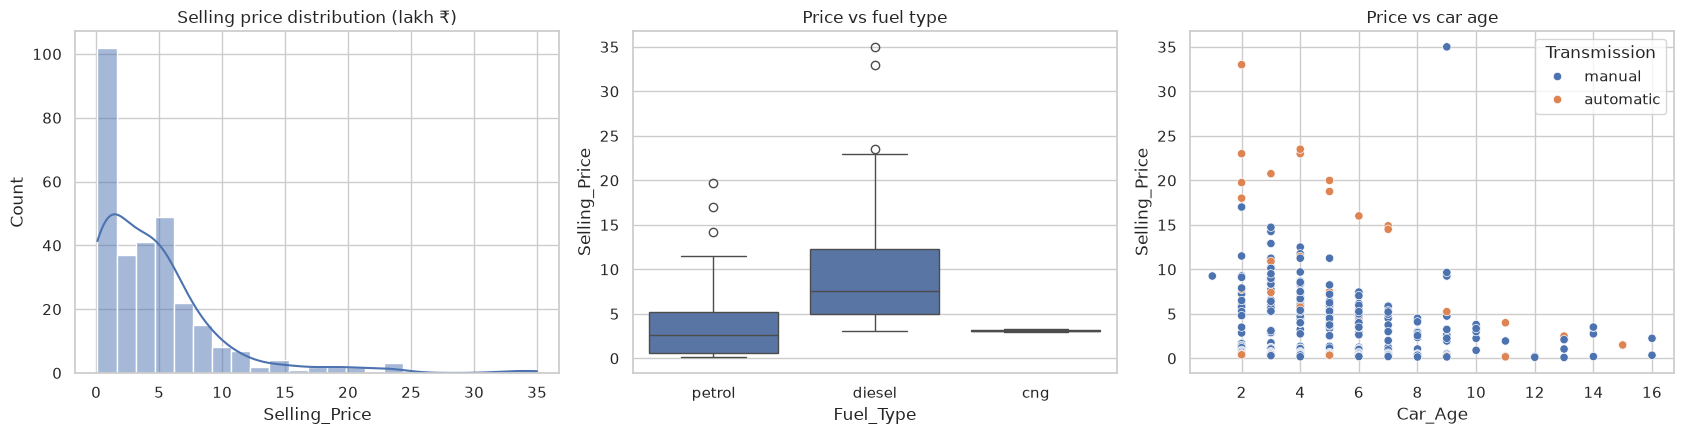

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(df["Selling_Price"], kde=True, ax=ax[0]).set_title("Selling price distribution (lakh ₹)")
sns.boxplot(data=df, x="Fuel_Type", y="Selling_Price", ax=ax[1]).set_title("Price vs fuel type")
sns.scatterplot(data=df, x="Car_Age", y="Selling_Price", hue="Transmission", ax=ax[2]).set_title("Price vs car age")
save("eda")

**Observations:** Prices are strongly right-skewed: most cars sell for under 10 lakh, with a long tail of premium cars. Diesel cars sell for clearly more than petrol cars. Price falls as the car gets older, and automatic cars tend to sit toward the top of the price range.

## 4. Encoding & correlation

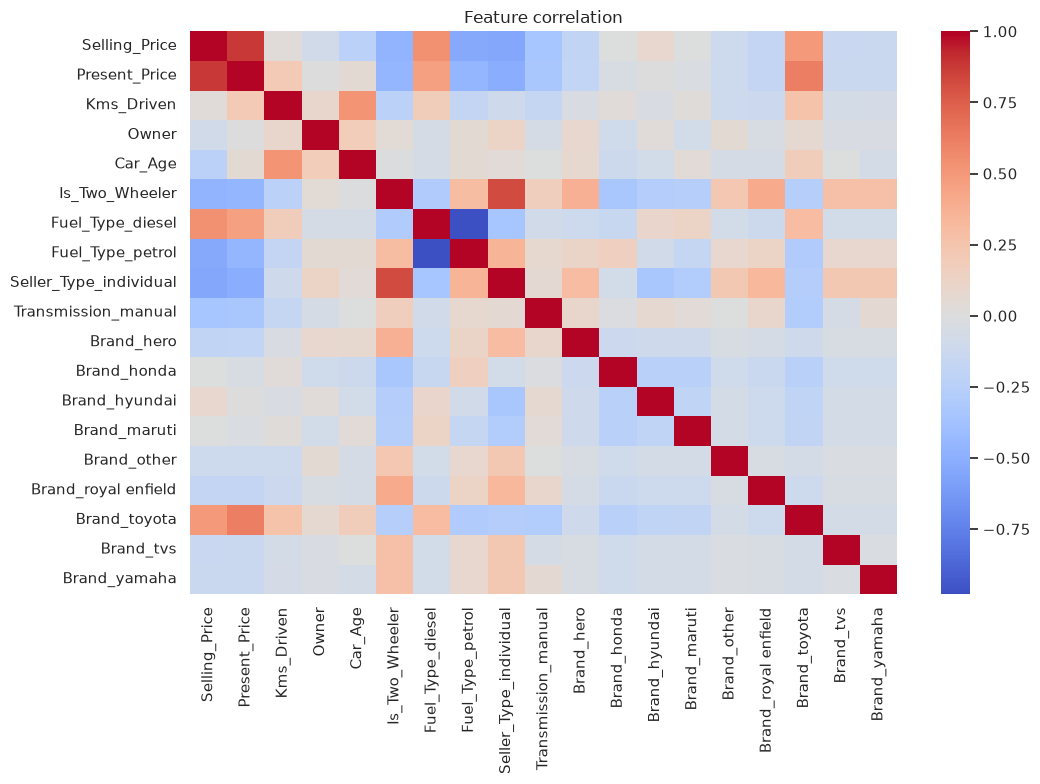

Selling_Price       1.00
Present_Price       0.88
Fuel_Type_diesel    0.54
Brand_toyota        0.50
Brand_hyundai       0.08
Kms_Driven          0.03
Brand_maruti        0.00
Brand_honda        -0.00
Name: Selling_Price, dtype: float64

In [6]:
data = pd.get_dummies(df.drop(columns=["Car_Name", "Year"]), columns=["Fuel_Type", "Seller_Type", "Transmission", "Brand"], drop_first=True, dtype=int)
plt.figure(figsize=(11, 8)); sns.heatmap(data.corr(), cmap="coolwarm", center=0); plt.title("Feature correlation"); save("correlation")
data.corr()["Selling_Price"].sort_values(ascending=False).round(2).head(8)

## 5. Train/test split and models
Prices are right-skewed, so each model is trained on **log(1 + price)** and its predictions are converted back to lakh ₹ for evaluation.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
X, y = data.drop(columns="Selling_Price"), data["Selling_Price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
models = {"Linear Regression": LinearRegression(),
          "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42),
          "Gradient Boosting": GradientBoostingRegressor(random_state=42)}
rows = []
for name, m in models.items():
    m.fit(X_train, np.log1p(y_train)); p = np.expm1(m.predict(X_test))   # train on log(price), report on lakh scale
    rows.append({"Model": name, "MAE": mean_absolute_error(y_test, p), "RMSE": mean_squared_error(y_test, p) ** 0.5, "R2": r2_score(y_test, p)})
res = pd.DataFrame(rows).set_index("Model").sort_values("R2", ascending=False).round(3); res

,MAE,RMSE,R2
Model,,,
Linear Regression,0.959,1.637,0.896
Gradient Boosting,0.918,1.941,0.854
Random Forest,1.307,3.086,0.630


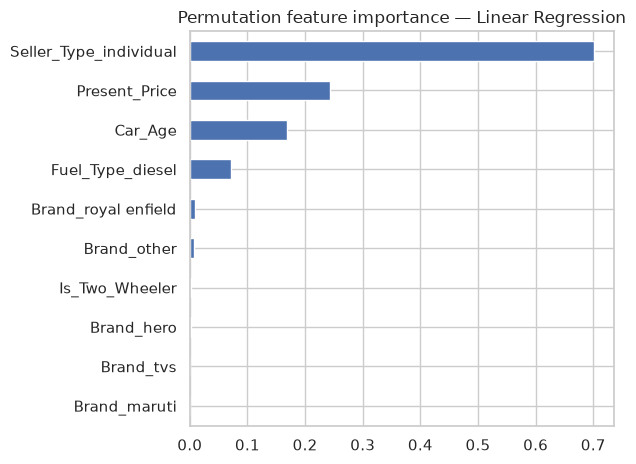

Seller_Type_individual    0.701
Present_Price             0.243
Car_Age                   0.168
Fuel_Type_diesel          0.071
Brand_royal enfield       0.008
Brand_other               0.006
Is_Two_Wheeler            0.002
Brand_hero                0.001
Brand_tvs                 0.001
Brand_maruti              0.001
dtype: float64


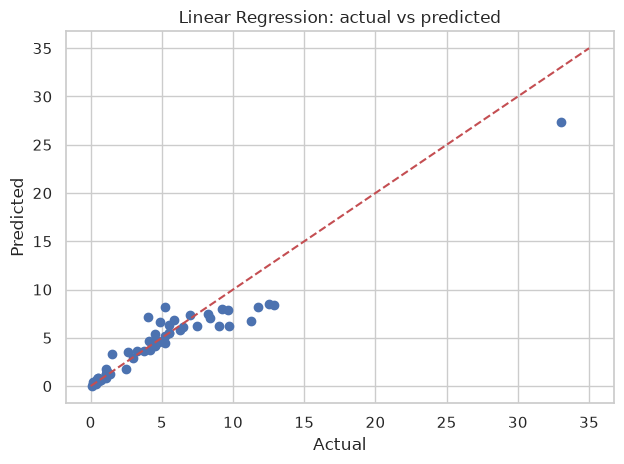

Best model: Linear Regression


In [8]:
best_name = res.index[0]; best = models[best_name]
from sklearn.inspection import permutation_importance   # model-agnostic, works for any best model
pi = permutation_importance(best, X_test, np.log1p(y_test), n_repeats=30, random_state=42)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values().tail(10)
imp.plot.barh(title=f"Permutation feature importance — {best_name}"); save("feature_importance")
print(imp.sort_values(ascending=False).round(3))
p = np.expm1(best.predict(X_test)); plt.scatter(y_test, p); plt.plot([0, y.max()], [0, y.max()], "r--"); plt.xlabel("Actual"); plt.ylabel("Predicted"); plt.title(f"{best_name}: actual vs predicted"); save("actual_vs_predicted")
print("Best model:", best_name)

## 6. Conclusion
- With a log-transformed target, **Linear Regression is the best model** (R² ≈ 0.90, RMSE ≈ 1.64 lakh). On the log scale, depreciation is close to multiplicative, so a linear model fits it well. Gradient Boosting comes second (R² ≈ 0.85). Random Forest is hurt by a few high-priced outliers in this small 60-car test set.
- **Permutation importance** for the best model ranks **Seller_Type = individual** first. In this dataset, individual sellers are almost all two-wheelers, so this feature acts as a proxy for 'bike vs car'. After that come **Present_Price** (showroom price), **Car_Age** and **Fuel_Type = diesel**. Brand matters little once those are known.
- With only about 300 rows, the results are sensitive to the train/test split. More data, or cross-validation, would give more reliable rankings.